# TP 7 · Comparer un MLP et un CNN

Fashion-MNIST : images de vêtements 28 × 28 en niveaux de gris, **10 classes**. On prend **6 000 images de train et 1 000 de validation**, tirées du train officiel.

**Objectif :**
1. Charger FashionMNIST et vérifier un batch `[N, 1, 28, 28]`
2. Entraîner le MLP et le CNN avec le **même budget**
3. Comparer accuracy et confusion matrix sur validation
4. Examiner six erreurs et proposer une explication

**Différence avec les TP 3 à 6 :** on passe de 2 classes (panne / pas panne) à **10 classes**. Le modèle sort donc **10 logits**, la loss devient `CrossEntropyLoss`, et la prédiction est `argmax` (la classe au plus gros score). Les classes sont équilibrées, donc ici l'**accuracy** est une métrique correcte (contrairement à AI4I).

## 0. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

torch.manual_seed(42)

## 1. Charger Fashion-MNIST

- `ToTensor` : image → tensor `[C, H, W]` = `[1, 28, 28]`, pixels de 0–255 ramenés entre 0 et 1.
- `Normalize((0.5,), (0.5,))` : `(x − 0.5) / 0.5` → valeurs entre −1 et 1 (centrées sur 0, comme le StandardScaler du TP 1).
- `download=True` télécharge le dataset dans `data/FashionMNIST` la première fois, puis le réutilise.
- `stratify=full.targets` : exactement 600 images par classe en train et 100 en val.

In [2]:
tf = transforms.Compose([
    transforms.ToTensor(),                 # [0, 255] -> [0, 1], format [C, H, W]
    transforms.Normalize((0.5,), (0.5,)),  # [0, 1]   -> [-1, 1]
])
full = datasets.FashionMNIST("data", train=True, download=True, transform=tf)
CLASSES = full.classes
print(len(full), "images dans le train officiel")
print(CLASSES)

# 6 000 train + 1 000 validation, tirées du train officiel, stratifiées par classe
tr_idx, va_idx = train_test_split(range(len(full)), train_size=6000, test_size=1000,
                                  stratify=full.targets, random_state=42)
print(len(tr_idx), len(va_idx))

60000 images dans le train officiel
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
6000 1000


### Vérifier un batch

Format PyTorch d'un batch d'images : **`[N, C, H, W]`** = nombre d'images, canaux, hauteur, largeur.

In [3]:
train_loader = DataLoader(Subset(full, tr_idx), batch_size=64, shuffle=True)
xb, yb = next(iter(train_loader))
print(xb.shape, xb.dtype)
print(yb.shape, yb.dtype)
print(xb.min().item(), xb.max().item())

torch.Size([64, 1, 28, 28]) torch.float32
torch.Size([64]) torch.int64
-1.0 1.0


**Lecture :** `[64, 1, 28, 28]` ✅ — 64 images, 1 canal (gris), 28 × 28. Les labels sont des entiers `int64` (le numéro de la classe, 0 à 9), et les valeurs vont de −1 à 1 grâce à `Normalize`.

### Mettre les données en mémoire

Passer par le `DataLoader` relit et transforme chaque image à chaque epoch. Comme 7 000 images 28 × 28 ne pèsent presque rien, on les met directement dans deux tensors : même contenu (vérifié ci-dessous), entraînement bien plus rapide. C'est ce que fait le cours avec `load_digits` (boucle `randperm(...).split(64)`).

In [4]:
# 7 000 petites images tiennent en mémoire : on les met dans deux gros tensors
# (même résultat que passer par transform, mais l'entraînement est beaucoup plus rapide)
X_all = ((full.data.float() / 255) - 0.5) / 0.5   # même normalisation que tf
X_all = X_all.unsqueeze(1)                          # [60000, 28, 28] -> [60000, 1, 28, 28]
y_all = full.targets

X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
print(X_tr.shape, y_tr.shape, X_va.shape)
print("même valeurs que le DataLoader :", torch.allclose(X_tr[0], full[tr_idx[0]][0]))
print("images par classe (train) :", torch.bincount(y_tr).tolist())
print("images par classe (val)   :", torch.bincount(y_va).tolist())

torch.Size([6000, 1, 28, 28]) torch.Size([6000]) torch.Size([1000, 1, 28, 28])
même valeurs que le DataLoader : True
images par classe (train) : [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
images par classe (val)   : [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


**Lecture :** 600 images par classe en train, 100 en val → classes parfaitement équilibrées. Un modèle au hasard aurait 10 % d'accuracy.

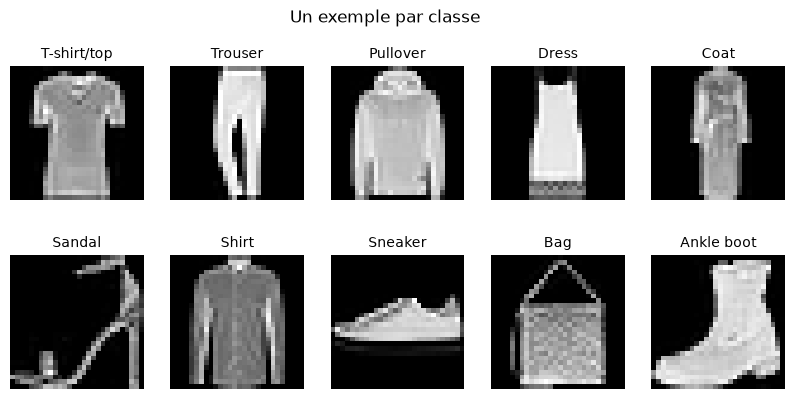

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for k, ax in enumerate(axes.flat):
    i = (y_tr == k).nonzero()[0].item()
    ax.imshow(X_tr[i].squeeze(), cmap="gray")
    ax.set_title(CLASSES[k], fontsize=10)
    ax.axis("off")
plt.suptitle("Un exemple par classe")
plt.show()

## 2. Les outils : accuracy et boucle d'entraînement

Même boucle que le cours (et que le TP 4), avec deux changements :
- `CrossEntropyLoss` au lieu de `BCEWithLogitsLoss` : elle prend les 10 logits et le numéro de la vraie classe.
- `accuracy` = `argmax(1)` puis proportion de bonnes réponses.

On enregistre à chaque epoch la loss et l'accuracy sur train **et** val, pour voir l'overfitting.

In [6]:
count = lambda m: sum(p.numel() for p in m.parameters())

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, X, y, Xv, yv, epochs=15, lr=1e-3, batch_size=64):
    """Même boucle que le cours : Adam, CrossEntropy, batches de 64 mélangés à chaque epoch."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for i in torch.randperm(len(X)).split(batch_size):
            opt.zero_grad()
            loss = loss_fn(model(X[i]), y[i])
            loss.backward()
            opt.step()
            total += loss.item() * len(i)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), yv).item()
        hist.append({"epoch": epoch + 1, "train_loss": total / len(X), "val_loss": val_loss,
                     "train_acc": accuracy(model, X, y), "val_acc": accuracy(model, Xv, yv)})
    return pd.DataFrame(hist)

## 3. Les deux modèles

| | MLP | CNN |
|---|---|---|
| Entrée | image **aplatie** en 784 nombres | image gardée en **2D** |
| Couches | Linear 784→64, ReLU, Linear 64→10 | 2 × (Conv 3×3 + ReLU + MaxPool), puis Linear 784→10 |
| Idée | chaque pixel a son propre weight | des petits filtres 3×3 glissent sur toute l'image (weights **partagés**) |

Le MLP perd le voisinage des pixels au `Flatten` : décaler l'objet d'un pixel, c'est montrer au réseau une entrée « nouvelle ». Le CNN cherche les mêmes motifs locaux (bords, coins…) partout dans l'image.

In [7]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),                 # [N, 1, 28, 28] -> [N, 784]
        nn.Linear(784, 64), nn.ReLU(),
        nn.Linear(64, 10),            # 10 logits, un par classe
    )

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 7 * 7, 10),
    )

print("MLP :", count(make_mlp()), "parameters")
print("CNN :", count(make_cnn()), "parameters")

x = torch.zeros(64, 1, 28, 28)
for layer in make_cnn():
    x = layer(x)
    print(f"{type(layer).__name__:<10}", list(x.shape))

MLP : 50890 parameters
CNN : 9098 parameters
Conv2d     [64, 8, 28, 28]
ReLU       [64, 8, 28, 28]
MaxPool2d  [64, 8, 14, 14]
Conv2d     [64, 16, 14, 14]
ReLU       [64, 16, 14, 14]
MaxPool2d  [64, 16, 7, 7]
Flatten    [64, 784]
Linear     [64, 10]


**Lecture :**
- MLP : **50 890** parameters, dont 50 240 rien que dans la première couche (784 × 64 + 64).
- CNN : **9 098** parameters, soit **5,6× moins**. Les deux convolutions ne coûtent que 80 + 1 168 parameters : leurs filtres sont réutilisés à toutes les positions.
- Dans le CNN, les canaux montent (1 → 8 → 16) pendant que la taille baisse (28 → 14 → 7) : on échange de la résolution contre des motifs plus riches.

## 4. Entraîner avec le même budget

« Même budget » = mêmes données, même seed, même optimizer (Adam, lr 1e-3), même batch (64), même nombre d'epochs (15). Seule l'architecture change, donc la comparaison est équitable.

In [8]:
# Même budget pour les deux : même seed, 15 epochs, Adam lr=1e-3, batch 64, mêmes données
EPOCHS = 15
models, hists, times = {}, {}, {}
for name, make in [("MLP", make_mlp), ("CNN", make_cnn)]:
    torch.manual_seed(42)
    m = make()
    t0 = time.time()
    hists[name] = fit(m, X_tr, y_tr, X_va, y_va, epochs=EPOCHS)
    times[name] = time.time() - t0
    models[name] = m
    print(f"{name} : {times[name]:.1f} s, val accuracy finale {hists[name].val_acc.iloc[-1]:.3f}")
mlp, cnn = models["MLP"], models["CNN"]

MLP : 1.8 s, val accuracy finale 0.856


CNN : 12.9 s, val accuracy finale 0.868


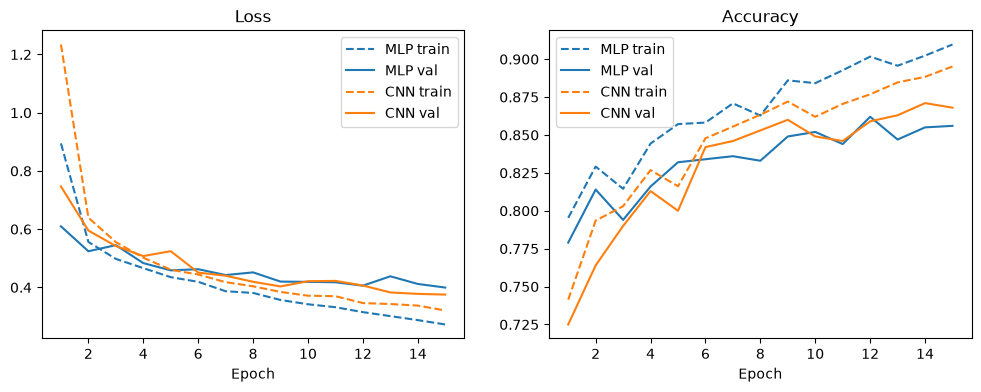

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, c in [("MLP", "tab:blue"), ("CNN", "tab:orange")]:
    h = hists[name]
    axes[0].plot(h.epoch, h.train_loss, "--", color=c, label=f"{name} train")
    axes[0].plot(h.epoch, h.val_loss, color=c, label=f"{name} val")
    axes[1].plot(h.epoch, h.train_acc, "--", color=c, label=f"{name} train")
    axes[1].plot(h.epoch, h.val_acc, color=c, label=f"{name} val")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()

**Lecture :**
- Les deux apprennent vite : ~80 % de val accuracy dès les premières epochs.
- **MLP** : la train loss continue de baisser mais la val loss stagne vers 0,40 à partir de l'epoch 9 environ → début d'**overfitting** (l'écart train/val se creuse).
- **CNN** : plus lent au départ, mais ses courbes train et val restent plus proches et sa val accuracy finit au-dessus.

## 5. Comparer

In [10]:
summary = pd.DataFrame({
    name: {"parameters": count(models[name]),
           "temps (s)": round(times[name], 1),
           "train acc": round(h.train_acc.iloc[-1], 3),
           "val acc (finale)": round(h.val_acc.iloc[-1], 3),
           "val acc (meilleure)": round(h.val_acc.max(), 3),
           "écart train - val": round(h.train_acc.iloc[-1] - h.val_acc.iloc[-1], 3)}
    for name, h in hists.items()}).T
summary

,parameters,temps (s),train acc,val acc (finale),val acc (meilleure),écart train - val
MLP,50890.0,1.8,0.910,0.856,0.862,0.054
CNN,9098.0,12.9,0.895,0.868,0.871,0.027


**Lecture :**
- **CNN 0,868** vs **MLP 0,856** en val accuracy finale : le CNN gagne d'un peu plus d'un point…
- … avec **5,6× moins de parameters**,
- et un **écart train − val deux fois plus petit** (0,027 vs 0,054) : il généralise mieux, il « apprend par cœur » moins.
- Contrepartie : il est **~7× plus lent** sur CPU (12,9 s vs 1,8 s), car une convolution fait beaucoup de calculs par parameter.

### Robustesse : une seule seed ne suffit pas

L'écart est d'environ 1 point. Est-ce le hasard de l'initialisation ? On relance chaque modèle avec 3 autres seeds.

In [11]:
# Une seule seed peut tromper : on relance chaque modèle avec 3 seeds différentes
rows = []
for seed in [0, 1, 2]:
    for name, make in [("MLP", make_mlp), ("CNN", make_cnn)]:
        torch.manual_seed(seed)
        h = fit(make(), X_tr, y_tr, X_va, y_va, epochs=EPOCHS)
        rows.append({"seed": seed, "modèle": name, "val acc finale": h.val_acc.iloc[-1],
                     "moyenne 3 dernières epochs": h.val_acc.iloc[-3:].mean()})
seeds = pd.DataFrame(rows)
print(seeds.round(3).to_string(index=False))
print()
print(seeds.groupby("modèle")[["val acc finale", "moyenne 3 dernières epochs"]].agg(["mean", "std"]).round(3))

 seed modèle  val acc finale  moyenne 3 dernières epochs
    0    MLP           0.842                       0.848
    0    CNN           0.876                       0.870
    1    MLP           0.837                       0.848
    1    CNN           0.861                       0.856
    2    MLP           0.848                       0.854
    2    CNN           0.862                       0.865

       val acc finale        moyenne 3 dernières epochs       
                 mean    std                       mean    std
modèle                                                        
CNN             0.866  0.008                      0.864  0.007
MLP             0.842  0.006                      0.850  0.003


**Lecture :** sur 3 seeds, CNN **0,866 ± 0,008** vs MLP **0,842 ± 0,006**. Le CNN gagne à **chaque** seed, avec un écart (~2 points) plus grand que la variation due au hasard → l'avantage du CNN est réel, pas un coup de chance.

### Confusion matrices

Ligne = vraie classe, colonne = prédiction. La diagonale = bonnes réponses ; on regarde d'abord les **grosses cases hors diagonale**.

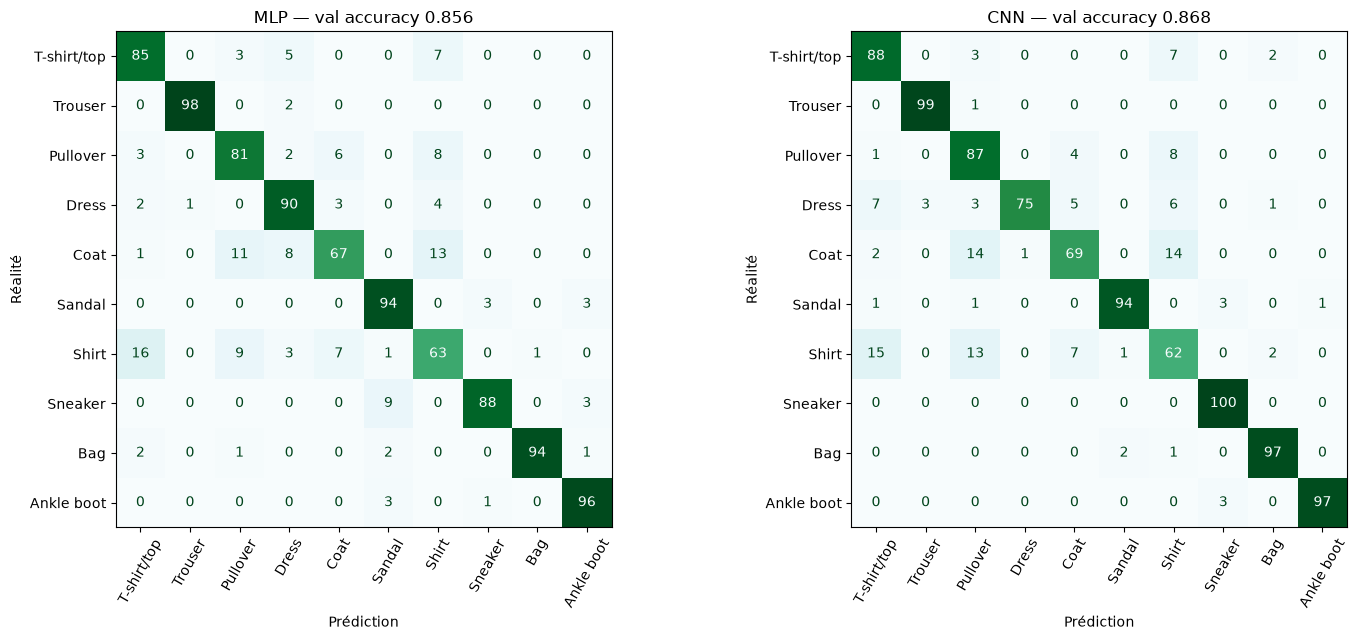

In [12]:
preds = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, name in zip(axes, ["MLP", "CNN"]):
    models[name].eval()
    with torch.no_grad():
        preds[name] = models[name](X_va).argmax(1)
    ConfusionMatrixDisplay.from_predictions(y_va, preds[name], display_labels=CLASSES,
                                            ax=ax, colorbar=False, cmap="BuGn",
                                            xticks_rotation=60)
    ax.set_title(f"{name} — val accuracy {(preds[name] == y_va).float().mean():.3f}")
    ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
plt.tight_layout()
plt.show()

**Lecture :**
- Faciles pour les deux : **Trouser, Bag, Ankle boot, Sandal, Sneaker** (formes très distinctes).
- Difficile pour les deux : le bloc **haut du corps** — T-shirt, Pullover, Coat, **Shirt**. La pire case : Shirt lu T-shirt (16 MLP, 15 CNN), puis Coat lu Shirt (13 / 14) et Coat lu Pullover (11 / 14).
- **Chaussures** : le MLP confond Sneaker et Sandal (9 erreurs), le CNN aucune → la forme locale (lanières ajourées vs tissu plein) est exactement ce qu'une convolution capte bien.
- Le CNN rate en revanche plus de **Dress** (75 vs 90), surtout lues T-shirt ou Coat.

### Recall par classe

Recall d'une classe = parmi les vraies images de cette classe, combien sont reconnues (bonus du TP).

In [13]:
recall = pd.DataFrame({
    name: classification_report(y_va, preds[name], target_names=CLASSES,
                                output_dict=True, zero_division=0)
    for name in ["MLP", "CNN"]})
recall = pd.DataFrame({name: {c: recall[name][c]["recall"] for c in CLASSES} for name in ["MLP", "CNN"]})
recall["écart CNN - MLP"] = recall["CNN"] - recall["MLP"]
recall.round(2).sort_values("CNN")

,MLP,CNN,écart CNN - MLP
Shirt,0.63,0.62,-0.01
Coat,0.67,0.69,0.02
Dress,0.90,0.75,-0.15
Pullover,0.81,0.87,0.06
T-shirt/top,0.85,0.88,0.03
Sandal,0.94,0.94,0.00
Ankle boot,0.96,0.97,0.01
Bag,0.94,0.97,0.03
Trouser,0.98,0.99,0.01
Sneaker,0.88,1.00,0.12


**Lecture :** **Shirt** est la classe la moins bien reconnue (~0,62 pour les deux), puis Coat (~0,68). Le CNN gagne nettement sur Sneaker (+0,12) et Pullover (+0,06), perd sur Dress (−0,15). Le gain global du CNN n'est donc pas uniforme : il vient surtout des chaussures et des hauts.

### Test du décalage

Le cours montrait que décaler une image d'un pixel fait chuter un MLP. On vérifie sur Fashion-MNIST, sans réentraîner.

In [14]:
# Décaler chaque image d'1 et 2 pixels vers la droite : le modèle reconnaît-il encore ?
print("          normal  +1 px  +2 px")
for name in ["MLP", "CNN"]:
    m = models[name]
    a0 = accuracy(m, X_va, y_va)
    a1 = accuracy(m, torch.roll(X_va, shifts=1, dims=3), y_va)
    a2 = accuracy(m, torch.roll(X_va, shifts=2, dims=3), y_va)
    print(f"{name:<8} {a0:>7.3f} {a1:>6.3f} {a2:>6.3f}")

          normal  +1 px  +2 px
MLP        0.856  0.765  0.571
CNN        0.868  0.835  0.739


**Lecture :**

| | normal | +1 px | +2 px |
|---|---|---|---|
| MLP | 0,856 | 0,765 (−9 pts) | **0,571** (−29 pts) |
| CNN | 0,868 | 0,835 (−3 pts) | **0,739** (−13 pts) |

Le CNN résiste **beaucoup** mieux au décalage : ses filtres retrouvent les mêmes motifs un pixel plus loin, et le MaxPool tolère de petits déplacements. Le MLP, lui, a appris « tel pixel à telle position ». Le CNN n'est pas parfaitement invariant non plus (−13 pts à 2 px) : la dernière couche Linear reste liée aux positions.

## 6. Six erreurs à expliquer

Plutôt que 6 erreurs au hasard, on prend les 6 où le CNN était **le plus sûr de lui** : ce sont les plus instructives (le modèle ne « doute » pas, il est convaincu d'autre chose).

132 erreurs sur 1000


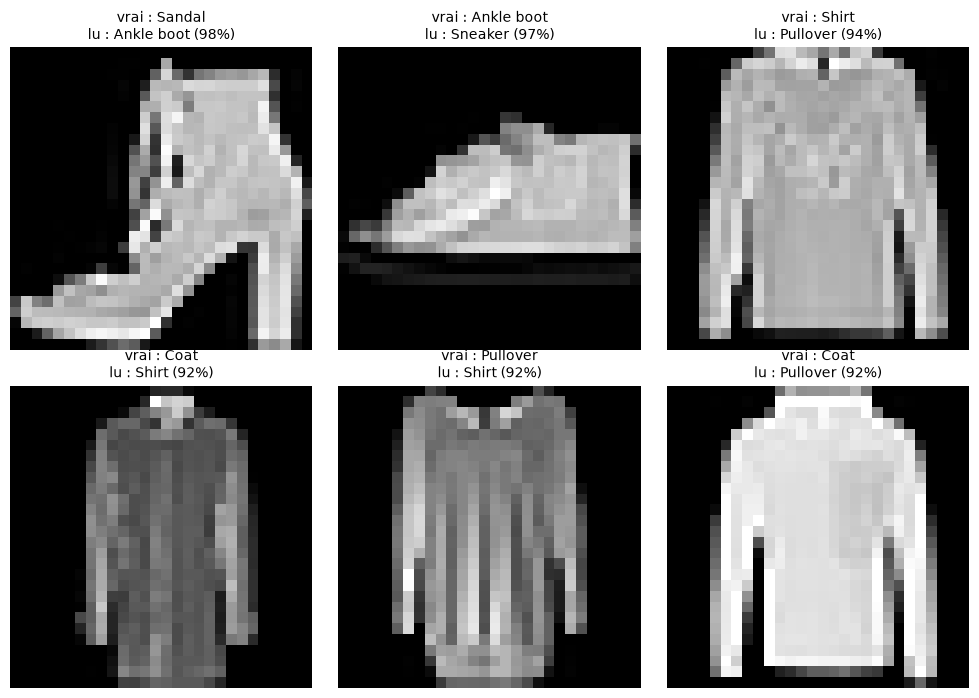

1 vrai=Sandal       prédit=Ankle boot   confiance=0.98 | MLP dit : Ankle boot
2 vrai=Ankle boot   prédit=Sneaker      confiance=0.97 | MLP dit : Sneaker
3 vrai=Shirt        prédit=Pullover     confiance=0.94 | MLP dit : Pullover
4 vrai=Coat         prédit=Shirt        confiance=0.92 | MLP dit : Coat
5 vrai=Pullover     prédit=Shirt        confiance=0.92 | MLP dit : Shirt
6 vrai=Coat         prédit=Pullover     confiance=0.92 | MLP dit : Pullover


In [15]:
# Six erreurs du CNN : celles où il était le PLUS sûr de lui (les plus instructives)
with torch.no_grad():
    probs = torch.softmax(cnn(X_va), dim=1)
conf, pred = probs.max(1)
wrong = (pred != y_va).nonzero().squeeze(1)
print(len(wrong), "erreurs sur", len(y_va))
worst = wrong[conf[wrong].argsort(descending=True)[:6]]

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, i in zip(axes.flat, worst):
    ax.imshow(X_va[i].squeeze(), cmap="gray")
    ax.set_title(f"vrai : {CLASSES[y_va[i]]}\nlu : {CLASSES[pred[i]]} ({conf[i]:.0%})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

for n, i in enumerate(worst.tolist(), 1):
    print(n, f"vrai={CLASSES[y_va[i]]:<12} prédit={CLASSES[pred[i]]:<12} confiance={conf[i]:.2f}",
          "| MLP dit :", CLASSES[preds['MLP'][i]])

**Lecture et explications** (132 erreurs sur 1000 au total) :

| # | Vrai → lu | Explication proposée |
|---|---|---|
| 1 | Sandal → Ankle boot (98 %) | L'image montre une **bottine à talon** fermée, sans lanières visibles. Le label « Sandal » est très discutable : probablement une **erreur ou ambiguïté de label** dans le dataset. Le MLP fait la même erreur. |
| 2 | Ankle boot → Sneaker (97 %) | Chaussure **basse**, sans tige montante : à 28 × 28 elle ressemble vraiment à une basket. Encore un cas où l'image ne correspond pas bien à sa classe. |
| 3 | Shirt → Pullover (94 %) | Manches longues, pas de boutons ni de col visibles : à cette résolution, les détails qui distinguent une chemise d'un pull **ont disparu**. |
| 4 | Coat → Shirt (92 %) | Manteau fin et sombre, sans fermeture visible : sa silhouette est celle d'une chemise. (Le MLP, lui, a bon ici.) |
| 5 | Pullover → Shirt (92 %) | Pull avec un **col** visible : le col est justement un indice « chemise » pour le modèle. |
| 6 | Coat → Pullover (92 %) | Manteau clair uni, sans ouverture ni poches visibles : même silhouette qu'un pull. |

**Bilan des erreurs :**
- Elles sont **concentrées entre classes proches** (hauts entre eux, chaussures entre elles), jamais absurdes (pas de sac lu pantalon).
- Plusieurs viennent de la **résolution** : 28 × 28 en gris efface boutons, fermetures, textures, qui sont justement ce qui sépare Shirt / Coat / Pullover.
- Certaines viennent probablement des **labels** eux-mêmes (#1, #2) : aucun modèle ne peut avoir raison contre un label faux.
- Le modèle est **très confiant même quand il se trompe** (92–98 %) : la confiance du softmax n'est pas une garantie.
- 5 erreurs sur 6 sont aussi faites par le MLP : ce sont des images difficiles, pas un défaut propre au CNN.

## 7. Bonus : ce que la première couche a appris

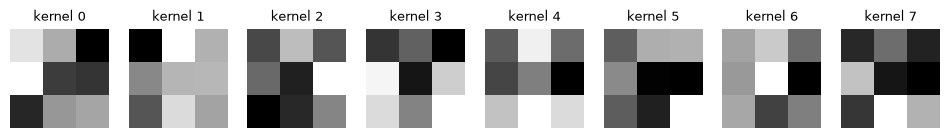

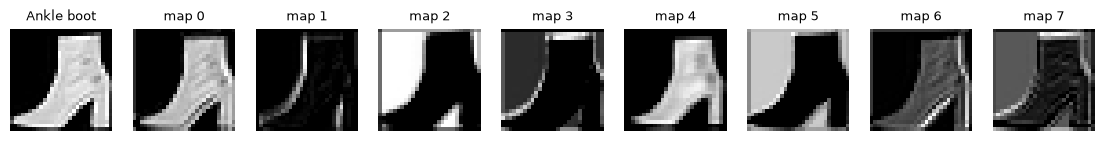

In [16]:
# Bonus : les 8 kernels 3x3 appris par la première convolution
w = cnn[0].weight.detach()
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for k, ax in enumerate(axes):
    ax.imshow(w[k, 0], cmap="gray")
    ax.set_title(f"kernel {k}", fontsize=9)
    ax.axis("off")
plt.show()

# Ce que ces kernels "voient" sur une image : les 8 feature maps
with torch.no_grad():
    fmap = torch.relu(cnn[0](X_va[:1]))[0]
fig, axes = plt.subplots(1, 9, figsize=(14, 2))
axes[0].imshow(X_va[0].squeeze(), cmap="gray"); axes[0].set_title(CLASSES[y_va[0]], fontsize=9)
for k in range(8):
    axes[k + 1].imshow(fmap[k], cmap="gray"); axes[k + 1].set_title(f"map {k}", fontsize=9)
for ax in axes: ax.axis("off")
plt.show()

**Lecture :** les kernels sont de petits motifs 3 × 3 de clair/foncé, **appris** par gradient descent (personne ne les a écrits). Sur les feature maps de la bottine : les maps 1, 6 et 7 font ressortir les **contours** (comme le filtre de Sobel du cours), les maps 0 et 4 reprennent l'**objet** lui-même, et les maps 2, 3 et 5 s'allument sur le **fond** (l'inverse de l'objet) : le réseau a appris tout seul à séparer silhouette, bords et arrière-plan. La deuxième convolution combine ensuite ces motifs simples en motifs plus complexes.

## 8. Conclusion

| | MLP | CNN |
|---|---|---|
| Parameters | 50 890 | **9 098** |
| Val accuracy (seed 42) | 0,856 | **0,868** |
| Val accuracy (3 seeds) | 0,842 ± 0,006 | **0,866 ± 0,008** |
| Écart train − val | 0,054 | **0,027** |
| Accuracy décalé de 2 px | 0,571 | **0,739** |
| Temps d'entraînement | **1,8 s** | 12,9 s |

- **Le CNN gagne** : ~1 à 2 points d'accuracy en plus, de manière stable sur plusieurs seeds, avec **5,6× moins de parameters**, moins d'overfitting et une bien meilleure résistance au décalage. C'est l'effet du **voisinage conservé** et des **weights partagés**.
- **Mais l'écart est modeste** sur Fashion-MNIST : les images sont petites, centrées et alignées, donc un MLP s'en sort déjà bien. Le gain du CNN grandirait avec des images plus grandes ou moins bien cadrées (cf. le test de décalage).
- **Limite persistante :** les deux butent sur les mêmes classes (Shirt / Coat / Pullover / T-shirt), à cause de la résolution et de labels parfois ambigus. Changer d'architecture ne suffit pas.
- **Prochaines expériences :** plus de kernels (16 puis 32), data augmentation sur le train seulement (flip horizontal, petits décalages), plus d'epochs avec sauvegarde du meilleur état (comme au TP 6).
- Le **test officiel** (10 000 images) n'a pas été utilisé : on le garde pour l'évaluation finale du modèle choisi.